# ISLR 9.7 #3 and Applied Exercises 7.

### 3(a) Sketch the observations

<img src="pro-3a.jpeg" alt="qb" width="50%">

### 3(b) Sketch the hyperplane

<img src="pro-3b.jpeg" alt="qb" width="50%">

### 3(c) describe the classification rule

Classify to red if 0.5 - x1 + x2 > 0 and classify to blue otherwise

### 3(d indicate the margin for maximal margin

<img src="pro-3d.jpeg" alt="qb" width="50%">

Margin is the band between the two dashed lines, half-width is the distance from the hyperplaen tot he nearest points, I got .354

### 3(e) indicate the support vectors for the maximal margin classifier

The four support vectors are 2, 3, 5, and 6 , these are the only points exactly on the margin, each at a distance of M = sqrt(2) / 4 from the hypotenuse

### 3(f) slight movement of 7th observation..

(4,1) has a distance of 1.77 from the hyperplane, which is much larger than the margin half-width M = 3.54, so it's not a suport vector.

The maximal margin hyperplane is determined only by the support vectors (observations 2, 3, 5 and 6). A slight movement of observation 7 keeps it far outside the margin and on the Blue side, so the same four points remain the closest ones and the hyperplane stays the same.

### 3(g) not optimal hyperplane and equation

<img src="pro-3g.png" alt="qb" width="50%">

Equation: 0.3 - x1 + x2 = 0

### 3(h) draw an additional observation

<img src="pro-3h.png" alt="qb" width="50%">

<sub>Drew a point at (2,3) so they are no longer separable by a hyperplane</sub>

# Applied #7

### 7(a) binary variable

In [1]:
library(ISLR2)

gas <- factor(ifelse(Auto$mpg > median(Auto$mpg), 1, 0))
dat <- data.frame(Auto[, !(names(Auto) %in% c("mpg", "name"))], gas = gas)

table(gas)

gas
  0   1 
196 196 

### 7(b) fit a support vector classifier

In [2]:
library(e1071)
set.seed(1)

tune.lin <- tune(svm, gas ~ ., data = dat, kernel = "linear",
                 ranges = list(cost = c(0.001, 0.01, 0.1, 1, 5, 10, 100)))

summary(tune.lin)                 # CV error for every cost value
tune.lin$performances             # same results as a data frame
tune.lin$best.parameters          # cost with the lowest CV error
tune.lin$best.performance         # that lowest CV error


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost
    1

- best performance: 0.08435897 

- Detailed performance results:
   cost      error dispersion
1 1e-03 0.13525641 0.05661708
2 1e-02 0.08923077 0.04698309
3 1e-01 0.09185897 0.04393409
4 1e+00 0.08435897 0.03662670
5 5e+00 0.08948718 0.03898410
6 1e+01 0.08948718 0.03898410
7 1e+02 0.08692308 0.03887151


cost,error,dispersion
<dbl>,<dbl>,<dbl>
1e-03,0.13525641,0.05661708
1e-02,0.08923077,0.04698309
1e-01,0.09185897,0.04393409
1e+00,0.08435897,0.03662670
5e+00,0.08948718,0.03898410
1e+01,0.08948718,0.03898410
1e+02,0.08692308,0.03887151


,cost
,<dbl>
4,1


[1] 0.08435897

### 7(c) repeat (b) using SVMs with radial and polynomial basis kernels

In [3]:
set.seed(1)

tune.rad <- tune(svm, gas ~ ., data = dat, kernel = "radial",
                 ranges = list(cost  = c(0.1, 1, 10, 100),
                               gamma = c(0.01, 0.1, 0.5, 1, 2, 3, 4)))

tune.pol <- tune(svm, gas ~ ., data = dat, kernel = "polynomial",
                 ranges = list(cost   = c(0.1, 1, 10, 100),
                               degree = c(2, 3, 4)))

summary(tune.rad)
summary(tune.pol)

data.frame(kernel = c("linear", "radial", "polynomial"),
           best_cv_error = c(tune.lin$best.performance,
                             tune.rad$best.performance,
                             tune.pol$best.performance))


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost gamma
    1     1

- best performance: 0.06634615 

- Detailed performance results:
    cost gamma      error dispersion
1    0.1  0.01 0.11224359 0.03836937
2    1.0  0.01 0.08673077 0.04551036
3   10.0  0.01 0.08673077 0.04040897
4  100.0  0.01 0.08685897 0.03483004
5    0.1  0.10 0.08923077 0.04698309
6    1.0  0.10 0.08923077 0.04376306
7   10.0  0.10 0.08166667 0.04149504
8  100.0  0.10 0.08410256 0.03390616
9    0.1  0.50 0.08666667 0.04687413
10   1.0  0.50 0.06884615 0.02963114
11  10.0  0.50 0.08923077 0.02732003
12 100.0  0.50 0.10698718 0.03512661
13   0.1  1.00 0.08673077 0.04535158
14   1.0  1.00 0.06634615 0.03244101
15  10.0  1.00 0.08923077 0.02732003
16 100.0  1.00 0.10448718 0.04560852
17   0.1  2.00 0.14282051 0.07578262
18   1.0  2.00 0.08673077 0.04371113
19  10.0  2.00 0.09429487 0.05387705
20 100.0  2.00 0.09435897 0.05261602
21   0.1  3.00 0.31878205 0.13973969
22


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost degree
   10      3

- best performance: 0.08416667 

- Detailed performance results:
    cost degree      error dispersion
1    0.1      2 0.29602564 0.06114607
2    1.0      2 0.27794872 0.08771788
3   10.0      2 0.18115385 0.04903946
4  100.0      2 0.17096154 0.04362330
5    0.1      3 0.18083333 0.13088037
6    1.0      3 0.10192308 0.04948784
7   10.0      3 0.08416667 0.03824016
8  100.0      3 0.09179487 0.03846724
9    0.1      4 0.26775641 0.07522220
10   1.0      4 0.25500000 0.06891932
11  10.0      4 0.17096154 0.06177989
12 100.0      4 0.13262821 0.04477243


kernel,best_cv_error
<chr>,<dbl>
linear,0.08435897
radial,0.06634615
polynomial,0.08416667


### 7(d) make some plots to back up assertions

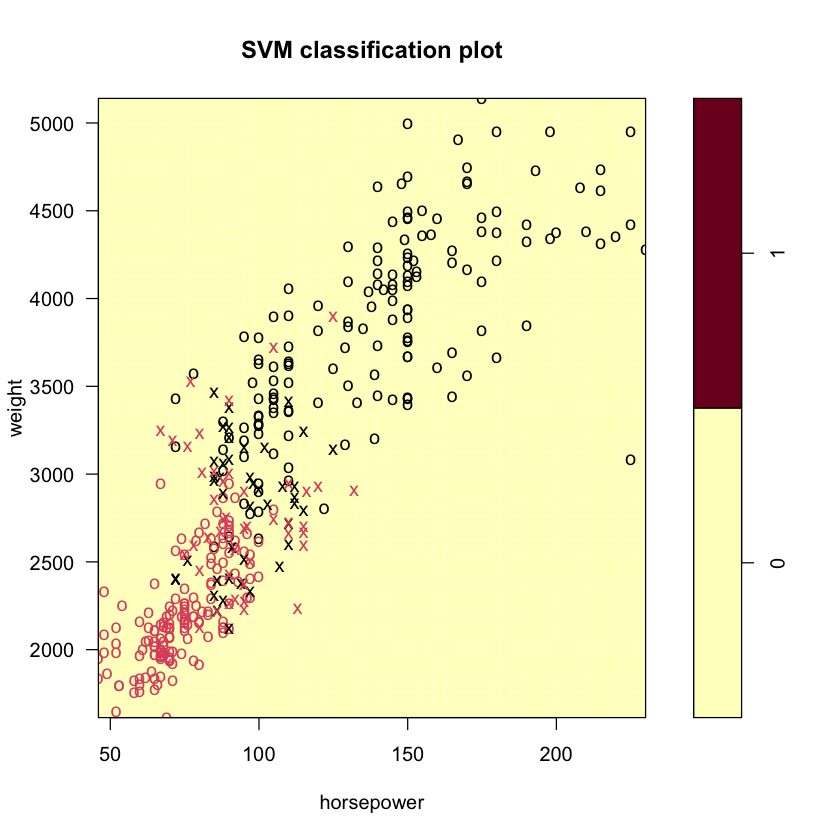

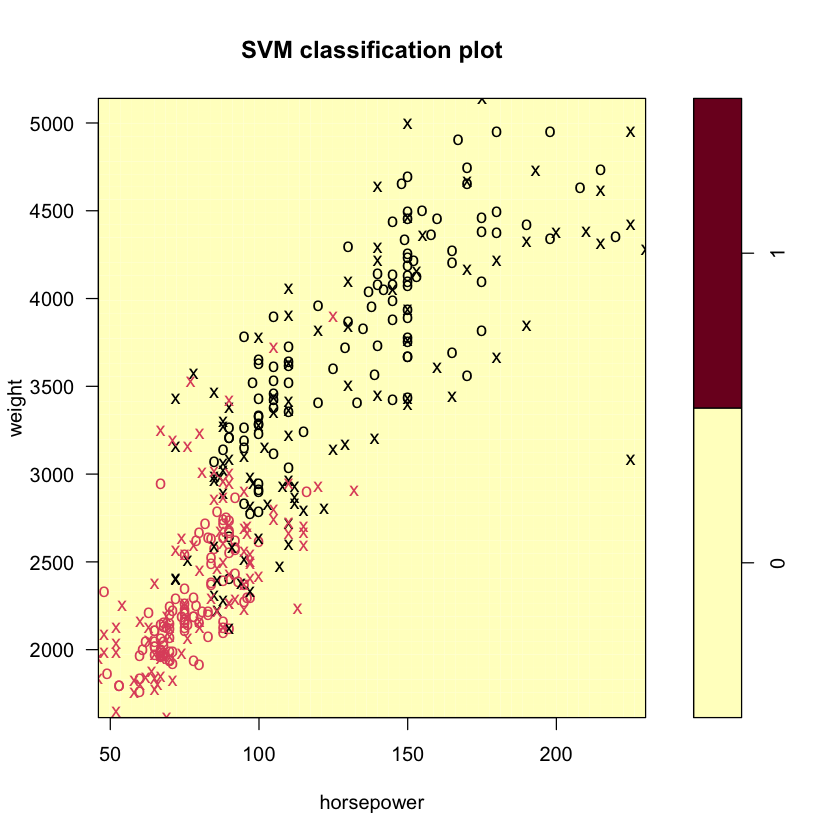

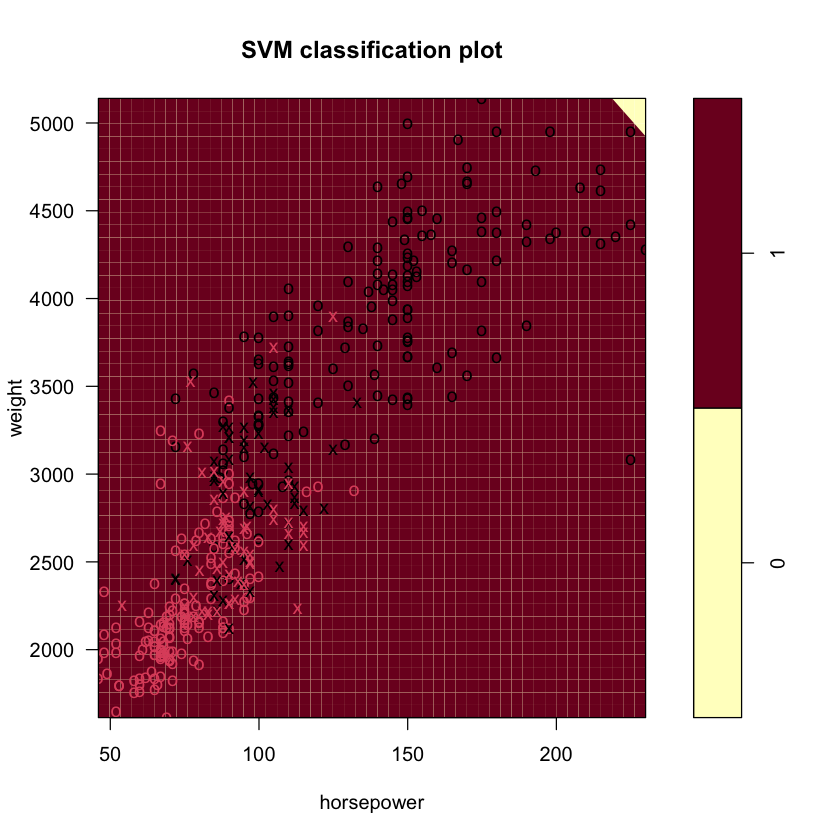

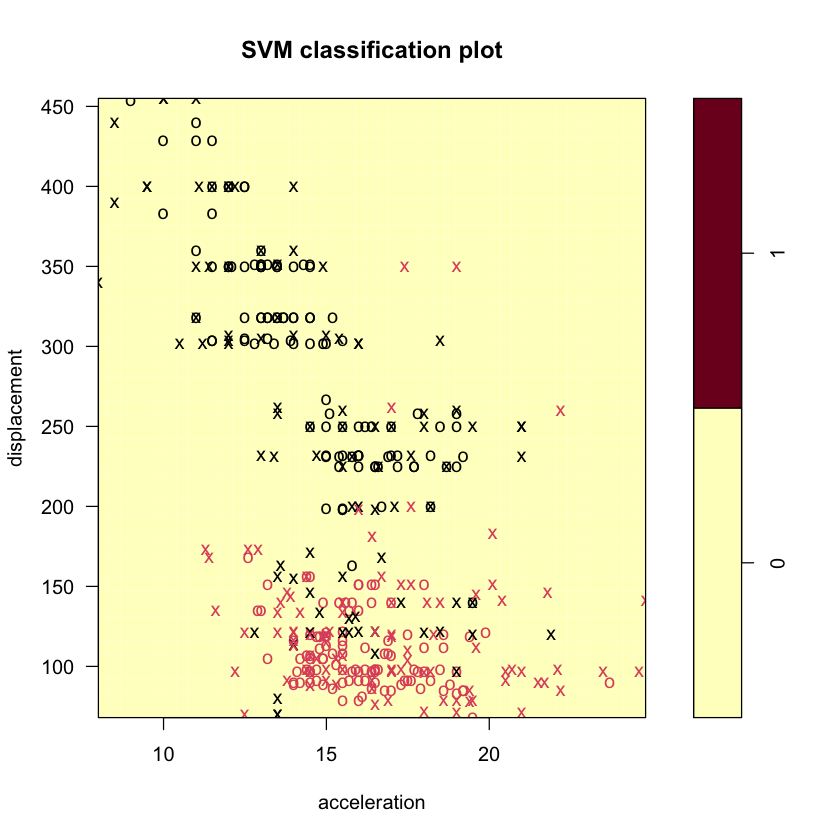

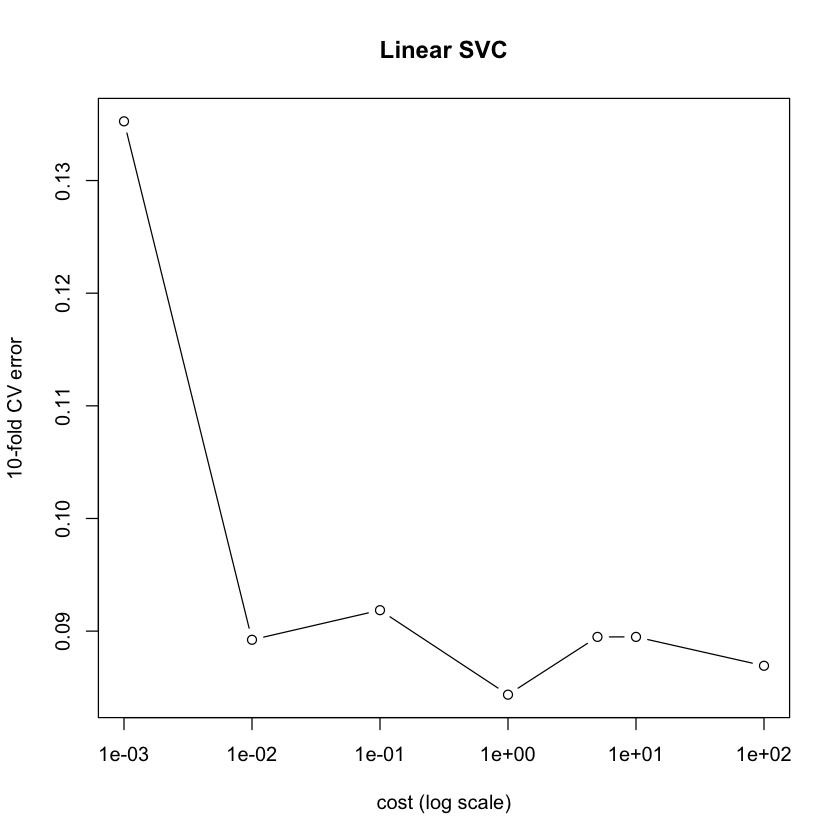

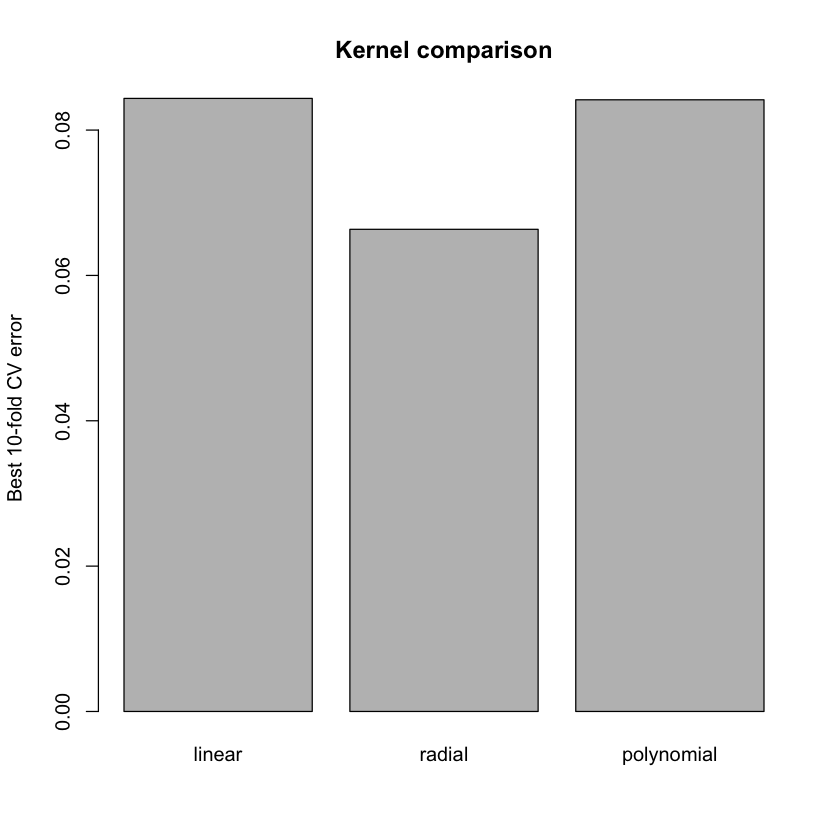

In [4]:
best.lin <- tune.lin$best.model
best.rad <- tune.rad$best.model
best.pol <- tune.pol$best.model

# Decision regions for two variables at a time (other variables held at 0, their scaled mean)
plot(best.lin, dat, weight ~ horsepower)
plot(best.rad, dat, weight ~ horsepower)
plot(best.pol, dat, weight ~ horsepower)

# A second pair of variables for the radial model
plot(best.rad, dat, displacement ~ acceleration)

# CV error vs. cost for the linear classifier (backs up part b)
plot(tune.lin$performances$cost, tune.lin$performances$error, type = "b", log = "x",
     xlab = "cost (log scale)", ylab = "10-fold CV error", main = "Linear SVC")

# Best CV error by kernel (backs up part c)
barplot(c(linear     = tune.lin$best.performance,
          radial     = tune.rad$best.performance,
          polynomial = tune.pol$best.performance),
        ylab = "Best 10-fold CV error", main = "Kernel comparison")